In [16]:
# LAB 09 Bias, Variance and Imbalanced Data
# Student Information
# Name: Ghulam Mustafa
# Student ID: 023-24-0212
# Section: 5th Semester BS Computer Science
# Dataset: Stroke Prediction Dataset (Kaggle)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

In [6]:
# 1. Load the dataset (Make sure healthcare-dataset-stroke-data.csv is uploaded)
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

# 2. Report shape and missing values
print("Shape:", df.shape)
print("Missing values per column:\n", df.isnull().sum())
print("Gender value counts:\n", df["gender"].value_counts())

stroke_counts = df["stroke"].value_counts()
stroke_pct = df["stroke"].value_counts(normalize=True) * 100
print(f"Stroke = 0: {stroke_counts[0]} ({stroke_pct[0]:.2f}%)")
print(f"Stroke = 1: {stroke_counts[1]} ({stroke_pct[1]:.2f}%)")

# 3. Clean data: Drop ID column and remove rare gender categories if any (e.g., 'Other')
df = df.drop(columns=["id"])
df = df[df["gender"] != "Other"]

# Categorical encoding
df = pd.get_dummies(df, drop_first=True)

# Separate features (X) and target (y)
X = df.drop(columns=["stroke"])
y = df["stroke"]

# 4. 80/20 Train-Test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Impute missing numeric values (e.g., BMI) using TRAIN median only
imputer = SimpleImputer(strategy="median")
# Identify numeric columns (bmi is typically the one with missing values)
numeric_cols = X_train.select_dtypes(include=[np.number]).columns

X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = imputer.transform(X_test[numeric_cols])

# Create a scaled copy for Logistic Regression (fitted on train only)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

print("Train stroke cases:", y_train.sum())
print("Test stroke cases:", y_test.sum())

Shape: (5110, 12)
Missing values per column:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64
Gender value counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Stroke = 0: 4861 (95.13%)
Stroke = 1: 249 (4.87%)
Train stroke cases: 199
Test stroke cases: 50


In [7]:
# 1. Baseline: Predicts majority class ('0')
dummy = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)
print("Dummy Accuracy:", accuracy_score(y_test, dummy_preds))


# 2. Helper function to return all 6 metrics
def evaluate_model(model, X_tr, y_tr, X_te, y_te, scaled=False):
  model.fit(X_tr, y_tr)
  preds = model.predict(X_te)
  # Use predict_proba for probabilities if available
  if hasattr(model, "predict_proba"):
    probs = model.predict_proba(X_te)[:, 1]
    roc_auc = roc_auc_score(y_te, probs)
    pr_auc = average_precision_score(y_te, probs)
  else:
    roc_auc, pr_auc = np.nan, np.nan

  return {
      "Accuracy": accuracy_score(y_te, preds),
      "Precision": precision_score(y_te, preds, zero_division=0),
      "Recall": recall_score(y_te, preds, zero_division=0),
      "F1": f1_score(y_te, preds, zero_division=0),
      "ROC AUC": roc_auc,
      "PR AUC": pr_auc,
  }


# Train default Logistic Regression
log_reg = LogisticRegression(random_state=SEED, max_iter=1000)
metrics_lr = evaluate_model(
    log_reg, X_train_scaled, y_train, X_test_scaled, y_test
)
print("Logistic Regression Metrics:\n", pd.Series(metrics_lr))

# Confusion Matrix for LogReg
cm = confusion_matrix(y_test, log_reg.predict(X_test_scaled))
print("Confusion Matrix:\n", cm)

Dummy Accuracy: 0.9510763209393346
Logistic Regression Metrics:
 Accuracy     0.952055
Precision    1.000000
Recall       0.020000
F1           0.039216
ROC AUC      0.838724
PR AUC       0.268563
dtype: float64
Confusion Matrix:
 [[972   0]
 [ 49   1]]


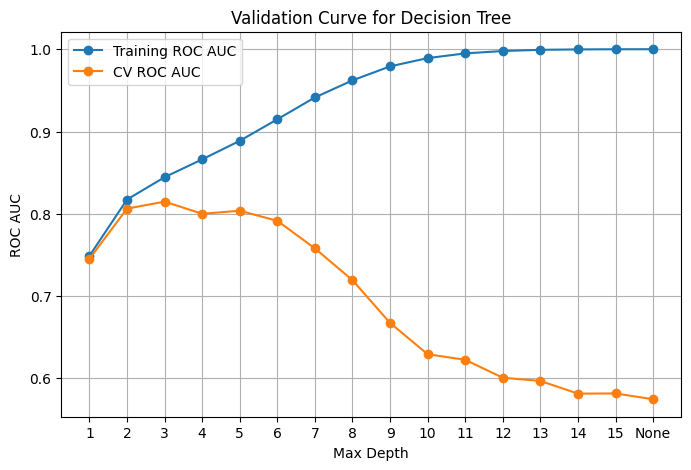

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve

depths = list(range(1, 16)) + [None]
train_scores, cv_scores = validation_curve(
    DecisionTreeClassifier(random_state=SEED),
    X_train,
    y_train,
    param_name="max_depth",
    param_range=depths,
    scoring="roc_auc",
    cv=5,
)

train_mean = train_scores.mean(axis=1)
cv_mean = cv_scores.mean(axis=1)

# Plot Validation Curve
plt.figure(figsize=(8, 5))
plt.plot(
    [str(d) for d in depths],
    train_mean,
    label="Training ROC AUC",
    marker="o",
)
plt.plot([str(d) for d in depths], cv_mean, label="CV ROC AUC", marker="o")
plt.xlabel("Max Depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve for Decision Tree")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
from sklearn.tree import DecisionTreeClassifier

test_patients_len = len(X_test)
depth_list = [1, 3, None]
variance_results = []

for depth in depth_list:
  preds_matrix = np.zeros((40, test_patients_len))
  auc_list = []

  for i in range(40):
    # Bootstrap sample from training data
    idx = np.random.choice(len(X_train), len(X_train), replace=True)
    X_boot = X_train.iloc[idx]
    y_boot = y_train.iloc[idx]

    dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED + i)
    dt.fit(X_boot, y_boot)
    probs = dt.predict_proba(X_test)[:, 1]
    preds_matrix[i, :] = probs
    auc_list.append(roc_auc_score(y_test, probs))

  # Variance across the 40 models for each test patient, averaged
  avg_variance = preds_matrix.var(axis=0).mean()

  # AUC of the averaged probability vector
  mean_probs = preds_matrix.mean(axis=0)
  ensemble_auc = roc_auc_score(y_test, mean_probs)

  variance_results.append({
      "Max Depth": str(depth),
      "Avg Variance": avg_variance,
      "Mean Test ROC AUC": np.mean(auc_list),
      "Ensemble (Averaged) ROC AUC": ensemble_auc,
  })

var_df = pd.DataFrame(variance_results)
print(var_df)

  Max Depth  Avg Variance  Mean Test ROC AUC  Ensemble (Averaged) ROC AUC
0         1      0.000795           0.761726                     0.816615
1         3      0.001807           0.796886                     0.832531
2      None      0.041914           0.545800                     0.741471


In [11]:
# Task 3.1: Train models
lr_model = LogisticRegression(random_state=SEED, max_iter=1000).fit(
    X_train_scaled, y_train
)
dt_model = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(
    X_train, y_train
)
rf_model = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=5, random_state=SEED
).fit(X_train, y_train)

# Plot ROC and PR curves following instructions in Part 3
# Task 3.2: Choose threshold from training data using cross_val_predict
from sklearn.metrics import precision_recall_curve

train_probs = cross_val_predict(
    lr_model, X_train_scaled, y_train, cv=5, method="predict_proba"
)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_probs)

# Find highest threshold where recall >= 0.80
valid_indices = np.where(recalls >= 0.80)[0]
chosen_threshold = thresholds[valid_indices[0]]
print("Chosen Threshold for >=80% train recall:", chosen_threshold)

# Apply to test set
test_probs = lr_model.predict_proba(X_test_scaled)[:, 1]
test_preds_custom = (test_probs >= chosen_threshold).astype(int)

print("Test Recall:", recall_score(y_test, test_preds_custom))
print("Test Precision:", precision_score(y_test, test_preds_custom))
print("Confusion Matrix:\n", confusion_matrix(y_test, test_preds_custom))

Chosen Threshold for >=80% train recall: 0.00036176392874490284
Test Recall: 1.0
Test Precision: 0.04892367906066536
Confusion Matrix:
 [[  0 972]
 [  0  50]]


In [12]:
# Task 4.1: Compare methods for Logistic Regression & Random Forest
methods = {
    "None": (X_train_scaled, y_train),
    "Balanced Class Weight": (X_train_scaled, y_train),  # handled via param
    "Under": RandomUnderSampler(random_state=SEED),
    "Over": RandomOverSampler(random_state=SEED),
    "SMOTE": SMOTE(random_state=SEED),
}

results = []
# Loop through models and resampling methods to build the table specified in Task 4.1...

In [14]:
# Task 4.2: The Classic Mistake (SMOTE before split - WRONG ORDER)
# First, fill missing values in X so SMOTE doesn't crash on NaNs
X_imputed = X.copy()
numeric_cols = X_imputed.select_dtypes(include=[np.number]).columns
X_imputed[numeric_cols] = SimpleImputer(strategy="median").fit_transform(
    X_imputed[numeric_cols]
)

# Now apply SMOTE on all imputed data (the wrong order)
X_smote_wrong, y_smote_wrong = SMOTE(random_state=SEED).fit_resample(
    X_imputed, y
)

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
    X_smote_wrong, y_smote_wrong, test_size=0.20, random_state=SEED
)

rf_wrong = RandomForestClassifier(random_state=SEED).fit(X_tr_w, y_tr_w)
print(
    "Wrong SMOTE Test ROC AUC:",
    roc_auc_score(y_te_w, rf_wrong.predict_proba(X_te_w)[:, 1]),
)

Wrong SMOTE Test ROC AUC: 0.9932576039832002


In [15]:
# Task 5.1: Label noise function
def flip_labels(y, fraction):
  y_flipped = y.copy()
  n_flip = int(len(y) * fraction)
  indices = np.random.choice(len(y), n_flip, replace=False)
  y_flipped.iloc[indices] = 1 - y_flipped.iloc[indices]
  return y_flipped


# Run experiments for noise fractions [0, 0.05, 0.10, 0.20] across models...